In this notebook I will try to implement the base Genetic Algorithm for the project by myself

The goal of the project is to create and run a Genetic Algorithm to approximate the Vermeer's "Girl with a pearl earring" painting using just 100 triangles.

The fitness will be the RMSE score of pixel by pixel comparison of the images

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from copy import deepcopy

Let's start by visualizing the goal image:

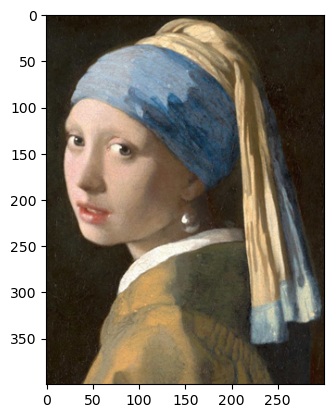

In [ ]:
target_image = Image.open("girl_pearl_earing.png")

plt.imshow(target_image)
plt.show()

Now let's define the solution class:

In [354]:
class Solution:
    
    def __init__(self, width, height, n_triangles, target_image: np.ndarray, representation = None) -> None:
        
        self.width = width
        self.height = height
        self.n_triangles = n_triangles
        
        if representation == None:
            self.representation = self.random_representation()
        else:
            self.representation = representation

        self.target_image = target_image
    
    def random_representation(self):
        # format of our individual triangle is:
        # [x1, y1, x2, y2, x3, y3, r, g, b, alpha]

        representation = np.empty((self.n_triangles, 10), dtype=int)

        # fill x coordinates (columns 0, 2, 4)
        representation[:, [0, 2, 4]] = np.random.randint(0, self.width, size=(self.n_triangles, 3))

        # fill y coordinates (columns 1, 3, 5)
        representation[:, [1, 3, 5]] = np.random.randint(0, self.height, size=(self.n_triangles, 3))

        # fill color + alpha (columns 6, 7, 8, 9)
        representation[:, 6:] = np.random.randint(0, 255, size=(self.n_triangles, 4))

        return representation

    def render(self):
        image = Image.new("RGB", (self.width, self.height))
        draw = ImageDraw.Draw(image, "RGBA")

        for tri in self.representation:
            draw.polygon(
                [(tri[0], tri[1]), (tri[2], tri[3]), (tri[4], tri[5])],
                fill=(tri[6], tri[7], tri[8], tri[9])
            )

        return image.convert("RGBA")

    def calculate_fitness(self):
        solution_image = np.asarray(self.render(), dtype=np.uint8)

        # we need to convert to a bigger type because the difference in uint8 
        # will wrap around and give us incorrect results
        error = solution_image.astype(np.float16) - self.target_image.astype(np.float16)
        self.fitness = np.sqrt(np.mean(error ** 2))
        
        return self

In [297]:
IMAGE_PATH = "girl_pearl_earing.png"
IMAGE_WIDTH = 300
IMAGE_HEIGHT = 400
N_TRIANGLES = 100
TARGET_IMAGE = target_image = np.asarray(Image.open(IMAGE_PATH).convert("RGBA"), dtype=np.uint8)

example_solution = Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE)

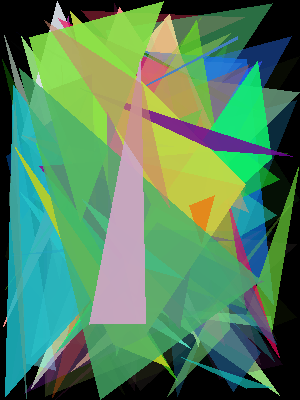

In [292]:
example_solution.render()

In [ ]:
example_solution.calculate_fitness()

np.float64(8.899437131077448)

Let's now start defining the genetic algorithm, we'll start by defining a tournament selection function, as it is often faster than roullete wheel and ranking selection because it doesn't need to calculate the fitness for all individuals

In [318]:
def tournament_selection(population: list[Solution], tournament_size) -> list[Solution]:
    
    selected = []
    
    for _ in range(len(population)):
        
        # Draw K individuals from the population with uniform probability and with replacement
        tournament: np.ndarray = np.random.choice(population, size=tournament_size, replace=True)
        
        # Select the best fitness inside the tournament
        winner = min(tournament, key=lambda individual: individual.fitness)
        selected.append(winner)
    
    return selected

Define a crossover function, let's try uniform crossover, where for each position, we exchange triangles with the other parent with a given probability

In [319]:
def crossover(parent1: Solution, parent2: Solution, crossover_rate: float) -> tuple[Solution, Solution]:
    
    if parent1.n_triangles != parent2.n_triangles:
        raise Exception("Parents did not have the same number of triangles.") 
    
    child1 = deepcopy(parent1)
    child2 = deepcopy(parent2)
    
    for i_triangle in range(parent1.n_triangles):
        if np.random.random() < crossover_rate:
            child2.representation[i_triangle] = parent1.representation[i_triangle]
            child1.representation[i_triangle] = parent2.representation[i_triangle]
            
    return child1, child2

Define a mutation function

In [321]:
def mutate(individual: Solution, mutation_rate: float) -> Solution:
    rep = individual.representation
    n = individual.n_triangles

    # boolean mask: True where a gene should mutate
    mask = np.random.random((n, 10)) < mutation_rate

    # generate all candidate new values upfront
    candidates = np.empty((n, 10), dtype=int)
    candidates[:, [0, 2, 4]] = np.random.randint(0, individual.width,  size=(n, 3))
    candidates[:, [1, 3, 5]] = np.random.randint(0, individual.height, size=(n, 3))
    candidates[:, 6:]        = np.random.randint(0, 255,               size=(n, 4))

    # apply mutations in one vectorized step
    rep[:] = np.where(mask, candidates, rep)

    return individual

Create the genetic algorithm loop

In [ ]:
from joblib import Parallel, delayed
import datetime

np.random.seed(33)

# required for pickling because of ProcessPoolExecutor
def _calculate_individual_fitness(individual: Solution):
    return individual.calculate_fitness()

def calculate_fitness_multithreaded(population: list[Solution], n_jobs: int = -1):
    # n_jobs=-1 uses all available CPU cores
    return Parallel(n_jobs=n_jobs, backend="loky")(
        delayed(_calculate_individual_fitness)(individual) for individual in population
    )
    
def genetic_algorithm_loop(
    population_size: int, 
    n_iterations: int, 
    tournament_size: int, 
    crossover_rate: float, 
    mutation_rate: float,
    mutation_rate_decay: float
) -> Solution:
    
    start_time = datetime.datetime.now()
    
    # create population with given size
    population = [ Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE) for _ in range(population_size) ]
    population = calculate_fitness_multithreaded(population)
    
    best_solution = population[0]
    best_fitness = population[0].fitness
    
    iteration_start_time = datetime.datetime.now()
    
    for i in range(n_iterations):
        
        # Selection phase
        parents = tournament_selection(population, tournament_size)
        
        offspring: list[Solution] = []
        # Reproduction with variation phase
        for j in range(0, len(parents), 2):
            parent1 = parents[j]
            parent2 = parents[j + 1] 
            
            child1, child2 = crossover(parent1, parent2, crossover_rate)
            
            child1 = mutate(child1, mutation_rate)
            child2 = mutate(child2, mutation_rate)
            
            offspring.extend([child1, child2])
        
        # Update the population and best solution
        population = calculate_fitness_multithreaded(offspring)
        population_fitness = [ individual.fitness for individual in population ]
        average_fitness = np.average(population_fitness)
        best_fitness_index = np.argmin(population_fitness)
        
        if population_fitness[best_fitness_index] <= best_fitness:
            best_fitness = population_fitness[best_fitness_index]
            best_solution = population[best_fitness_index]
        
        iteration_running_time = datetime.datetime.now() - iteration_start_time
        iteration_start_time = datetime.datetime.now()
        
        if ((i + 1) % 10 == 0 or i == 0):
            print(f"Iteration {i + 1} - Fitness: Avg: {average_fitness:.2f}, Best: {best_fitness:.2f}; Mutation rate: {mutation_rate:.3f}; {iteration_running_time.total_seconds():.2f}s/iteration")
        
        mutation_rate /= 1 + mutation_rate_decay
        
    return best_solution

In [358]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=50,
    n_iterations=100,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 63.97, Best: 58.78; Mutation rate: 0.050; 0.25s/iteration
Iteration 10 - Fitness: Avg: 54.69, Best: 49.75; Mutation rate: 0.050; 0.25s/iteration
Iteration 20 - Fitness: Avg: 53.66, Best: 47.50; Mutation rate: 0.049; 0.25s/iteration


KeyboardInterrupt: 

In [359]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=100,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 64.25, Best: 53.53; Mutation rate: 0.050; 0.94s/iteration
Iteration 10 - Fitness: Avg: 53.44, Best: 46.94; Mutation rate: 0.050; 0.90s/iteration
Iteration 20 - Fitness: Avg: 51.03, Best: 45.19; Mutation rate: 0.049; 0.90s/iteration
Iteration 30 - Fitness: Avg: 49.69, Best: 44.56; Mutation rate: 0.049; 0.89s/iteration
Iteration 40 - Fitness: Avg: 49.03, Best: 43.69; Mutation rate: 0.048; 0.87s/iteration
Iteration 50 - Fitness: Avg: 49.62, Best: 43.47; Mutation rate: 0.048; 0.82s/iteration
Iteration 60 - Fitness: Avg: 49.19, Best: 43.31; Mutation rate: 0.047; 0.88s/iteration
Iteration 70 - Fitness: Avg: 48.31, Best: 42.78; Mutation rate: 0.047; 0.85s/iteration
Iteration 80 - Fitness: Avg: 48.03, Best: 42.25; Mutation rate: 0.046; 0.87s/iteration
Iteration 90 - Fitness: Avg: 47.72, Best: 42.22; Mutation rate: 0.046; 0.84s/iteration
Iteration 100 - Fitness: Avg: 46.97, Best: 41.72; Mutation rate: 0.045; 0.86s/iteration


In [211]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=100,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.05,
    mutation_rate_decay=2e-3
)

Iteration 1 - Fitness: Avg: 8.90, Best: 8.72; Mutation rate: 0.050; 1.10s/iteration
Iteration 10 - Fitness: Avg: 8.57, Best: 8.35; Mutation rate: 0.049; 1.11s/iteration
Iteration 20 - Fitness: Avg: 8.46, Best: 8.23; Mutation rate: 0.048; 1.10s/iteration
Iteration 30 - Fitness: Avg: 8.38, Best: 8.14; Mutation rate: 0.047; 1.12s/iteration
Iteration 40 - Fitness: Avg: 8.31, Best: 8.01; Mutation rate: 0.046; 1.25s/iteration
Iteration 50 - Fitness: Avg: 8.22, Best: 7.95; Mutation rate: 0.045; 1.10s/iteration
Iteration 60 - Fitness: Avg: 8.20, Best: 7.95; Mutation rate: 0.044; 1.10s/iteration
Iteration 70 - Fitness: Avg: 8.22, Best: 7.95; Mutation rate: 0.044; 1.12s/iteration
Iteration 80 - Fitness: Avg: 8.22, Best: 7.95; Mutation rate: 0.043; 1.13s/iteration
Iteration 90 - Fitness: Avg: 8.15, Best: 7.91; Mutation rate: 0.042; 1.16s/iteration
Iteration 100 - Fitness: Avg: 8.16, Best: 7.90; Mutation rate: 0.041; 1.17s/iteration


In [214]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=50,
    n_iterations=400,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 8.92, Best: 8.85; Mutation rate: 0.050; 0.27s/iteration
Iteration 10 - Fitness: Avg: 8.75, Best: 8.61; Mutation rate: 0.050; 0.29s/iteration
Iteration 20 - Fitness: Avg: 8.64, Best: 8.48; Mutation rate: 0.049; 0.27s/iteration
Iteration 30 - Fitness: Avg: 8.64, Best: 8.43; Mutation rate: 0.049; 0.29s/iteration
Iteration 40 - Fitness: Avg: 8.62, Best: 8.42; Mutation rate: 0.048; 0.29s/iteration
Iteration 50 - Fitness: Avg: 8.57, Best: 8.35; Mutation rate: 0.048; 0.30s/iteration
Iteration 60 - Fitness: Avg: 8.53, Best: 8.32; Mutation rate: 0.047; 0.29s/iteration
Iteration 70 - Fitness: Avg: 8.54, Best: 8.32; Mutation rate: 0.047; 0.27s/iteration
Iteration 80 - Fitness: Avg: 8.52, Best: 8.30; Mutation rate: 0.046; 0.29s/iteration
Iteration 90 - Fitness: Avg: 8.48, Best: 8.26; Mutation rate: 0.046; 0.29s/iteration
Iteration 100 - Fitness: Avg: 8.49, Best: 8.26; Mutation rate: 0.045; 0.29s/iteration
Iteration 110 - Fitness: Avg: 8.41, Best: 8.19; Mutation rate: 0.

In [215]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=400,
    n_iterations=50,
    tournament_size=10,
    crossover_rate=0.8,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 8.91, Best: 8.76; Mutation rate: 0.050; 2.43s/iteration
Iteration 10 - Fitness: Avg: 8.63, Best: 8.44; Mutation rate: 0.050; 2.49s/iteration
Iteration 20 - Fitness: Avg: 8.44, Best: 8.20; Mutation rate: 0.049; 2.49s/iteration
Iteration 30 - Fitness: Avg: 8.34, Best: 8.06; Mutation rate: 0.049; 2.50s/iteration
Iteration 40 - Fitness: Avg: 8.30, Best: 8.05; Mutation rate: 0.048; 2.43s/iteration
Iteration 50 - Fitness: Avg: 8.27, Best: 7.95; Mutation rate: 0.048; 2.66s/iteration


In [332]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=1000,
    n_iterations=20,
    tournament_size=10,
    crossover_rate=0.8,
    mutation_rate=0.05,
    mutation_rate_decay=1e-2
)

Iteration 1 - Fitness: Avg: 58.23, Best: 49.80; Mutation rate: 0.050; 4.03s/iteration
Iteration 10 - Fitness: Avg: nan, Best: 24.50; Mutation rate: 0.046; 4.69s/iteration
Iteration 20 - Fitness: Avg: nan, Best: 11.58; Mutation rate: 0.041; 5.15s/iteration


In [216]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=100,
    tournament_size=10,
    crossover_rate=0.9,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 8.90, Best: 8.72; Mutation rate: 0.050; 1.37s/iteration
Iteration 10 - Fitness: Avg: 8.58, Best: 8.40; Mutation rate: 0.050; 1.11s/iteration
Iteration 20 - Fitness: Avg: 8.46, Best: 8.25; Mutation rate: 0.049; 1.10s/iteration
Iteration 30 - Fitness: Avg: 8.41, Best: 8.18; Mutation rate: 0.049; 1.13s/iteration
Iteration 40 - Fitness: Avg: 8.33, Best: 8.08; Mutation rate: 0.048; 1.24s/iteration
Iteration 50 - Fitness: Avg: 8.29, Best: 8.00; Mutation rate: 0.048; 1.13s/iteration
Iteration 60 - Fitness: Avg: 8.29, Best: 8.00; Mutation rate: 0.047; 1.12s/iteration
Iteration 70 - Fitness: Avg: 8.27, Best: 7.95; Mutation rate: 0.047; 1.11s/iteration
Iteration 80 - Fitness: Avg: 8.24, Best: 7.95; Mutation rate: 0.046; 1.08s/iteration
Iteration 90 - Fitness: Avg: 8.21, Best: 7.94; Mutation rate: 0.046; 1.07s/iteration
Iteration 100 - Fitness: Avg: 8.23, Best: 7.91; Mutation rate: 0.045; 1.11s/iteration


In [360]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=100,
    tournament_size=5,
    crossover_rate=0.7,
    mutation_rate=0.05,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 65.44, Best: 57.78; Mutation rate: 0.050; 0.85s/iteration
Iteration 10 - Fitness: Avg: 55.47, Best: 49.69; Mutation rate: 0.050; 0.98s/iteration
Iteration 20 - Fitness: Avg: 52.94, Best: 47.06; Mutation rate: 0.049; 1.05s/iteration
Iteration 30 - Fitness: Avg: 51.94, Best: 46.69; Mutation rate: 0.049; 0.99s/iteration
Iteration 40 - Fitness: Avg: 51.69, Best: 45.75; Mutation rate: 0.048; 0.92s/iteration
Iteration 50 - Fitness: Avg: 51.78, Best: 45.75; Mutation rate: 0.048; 0.87s/iteration
Iteration 60 - Fitness: Avg: 51.44, Best: 45.12; Mutation rate: 0.047; 0.84s/iteration
Iteration 70 - Fitness: Avg: 50.19, Best: 44.16; Mutation rate: 0.047; 0.90s/iteration
Iteration 80 - Fitness: Avg: 50.53, Best: 43.50; Mutation rate: 0.046; 0.94s/iteration
Iteration 90 - Fitness: Avg: 49.56, Best: 43.50; Mutation rate: 0.046; 0.88s/iteration
Iteration 100 - Fitness: Avg: 49.94, Best: 42.78; Mutation rate: 0.045; 0.89s/iteration


In [ ]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=100,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.10,
    mutation_rate_decay=2e-2
)

Iteration 1 - Fitness: Avg: 65.19, Best: 55.66; Mutation rate: 0.100; 0.85s/iteration
Iteration 10 - Fitness: Avg: 56.69, Best: 50.09; Mutation rate: 0.084; 0.88s/iteration
Iteration 20 - Fitness: Avg: 53.41, Best: 47.25; Mutation rate: 0.069; 0.87s/iteration
Iteration 30 - Fitness: Avg: 50.88, Best: 44.84; Mutation rate: 0.056; 0.82s/iteration
Iteration 40 - Fitness: Avg: 49.28, Best: 44.09; Mutation rate: 0.046; 0.90s/iteration
Iteration 50 - Fitness: Avg: 46.97, Best: 42.84; Mutation rate: 0.038; 0.88s/iteration
Iteration 60 - Fitness: Avg: 45.31, Best: 41.53; Mutation rate: 0.031; 0.84s/iteration
Iteration 70 - Fitness: Avg: 43.97, Best: 40.19; Mutation rate: 0.026; 0.87s/iteration
Iteration 80 - Fitness: Avg: 41.75, Best: 38.69; Mutation rate: 0.021; 0.88s/iteration
Iteration 90 - Fitness: Avg: 40.66, Best: 37.78; Mutation rate: 0.017; 0.90s/iteration
Iteration 100 - Fitness: Avg: 38.88, Best: 36.44; Mutation rate: 0.014; 0.90s/iteration


In [364]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=200,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.10,
    mutation_rate_decay=1e-2
)

Iteration 1 - Fitness: Avg: 65.19, Best: 55.66; Mutation rate: 0.100; 1.01s/iteration
Iteration 10 - Fitness: Avg: 58.09, Best: 52.06; Mutation rate: 0.091; 0.93s/iteration
Iteration 20 - Fitness: Avg: 55.94, Best: 49.34; Mutation rate: 0.083; 0.85s/iteration
Iteration 30 - Fitness: Avg: 54.09, Best: 46.09; Mutation rate: 0.075; 0.85s/iteration
Iteration 40 - Fitness: Avg: 53.12, Best: 46.09; Mutation rate: 0.068; 0.86s/iteration
Iteration 50 - Fitness: Avg: 51.16, Best: 44.16; Mutation rate: 0.061; 0.83s/iteration
Iteration 60 - Fitness: Avg: 51.00, Best: 44.16; Mutation rate: 0.056; 0.86s/iteration
Iteration 70 - Fitness: Avg: 49.81, Best: 42.34; Mutation rate: 0.050; 0.92s/iteration
Iteration 80 - Fitness: Avg: 48.25, Best: 42.34; Mutation rate: 0.046; 0.86s/iteration
Iteration 90 - Fitness: Avg: 47.22, Best: 41.16; Mutation rate: 0.041; 0.86s/iteration
Iteration 100 - Fitness: Avg: 46.66, Best: 40.41; Mutation rate: 0.037; 0.84s/iteration
Iteration 110 - Fitness: Avg: 46.22, Best: 

In [367]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=500,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.10,
    mutation_rate_decay=1e-2
)

Iteration 1 - Fitness: Avg: 65.19, Best: 55.66; Mutation rate: 0.100; 0.88s/iteration
Iteration 10 - Fitness: Avg: 58.09, Best: 52.06; Mutation rate: 0.091; 0.85s/iteration
Iteration 20 - Fitness: Avg: 55.94, Best: 49.34; Mutation rate: 0.083; 0.85s/iteration
Iteration 30 - Fitness: Avg: 54.09, Best: 46.09; Mutation rate: 0.075; 0.80s/iteration
Iteration 40 - Fitness: Avg: 53.12, Best: 46.09; Mutation rate: 0.068; 0.86s/iteration
Iteration 50 - Fitness: Avg: 51.16, Best: 44.16; Mutation rate: 0.061; 0.83s/iteration
Iteration 60 - Fitness: Avg: 51.00, Best: 44.16; Mutation rate: 0.056; 0.88s/iteration
Iteration 70 - Fitness: Avg: 49.81, Best: 42.34; Mutation rate: 0.050; 0.86s/iteration
Iteration 80 - Fitness: Avg: 48.25, Best: 42.34; Mutation rate: 0.046; 0.84s/iteration
Iteration 90 - Fitness: Avg: 47.22, Best: 41.16; Mutation rate: 0.041; 0.84s/iteration
Iteration 100 - Fitness: Avg: 46.66, Best: 40.41; Mutation rate: 0.037; 0.84s/iteration
Iteration 110 - Fitness: Avg: 46.22, Best: 

In [371]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=500,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.10,
    mutation_rate_decay=2e-2
)

Iteration 1 - Fitness: Avg: 65.19, Best: 55.66; Mutation rate: 0.100; 1.23s/iteration
Iteration 10 - Fitness: Avg: 56.69, Best: 50.09; Mutation rate: 0.084; 1.21s/iteration
Iteration 20 - Fitness: Avg: 53.41, Best: 47.25; Mutation rate: 0.069; 1.25s/iteration
Iteration 30 - Fitness: Avg: 50.88, Best: 44.84; Mutation rate: 0.056; 1.22s/iteration
Iteration 40 - Fitness: Avg: 49.28, Best: 44.09; Mutation rate: 0.046; 1.14s/iteration
Iteration 50 - Fitness: Avg: 46.97, Best: 42.84; Mutation rate: 0.038; 1.19s/iteration
Iteration 60 - Fitness: Avg: 45.31, Best: 41.53; Mutation rate: 0.031; 0.97s/iteration
Iteration 70 - Fitness: Avg: 43.97, Best: 40.19; Mutation rate: 0.026; 0.88s/iteration
Iteration 80 - Fitness: Avg: 41.75, Best: 38.69; Mutation rate: 0.021; 1.05s/iteration
Iteration 90 - Fitness: Avg: 40.66, Best: 37.78; Mutation rate: 0.017; 0.93s/iteration
Iteration 100 - Fitness: Avg: 38.88, Best: 36.44; Mutation rate: 0.014; 1.12s/iteration
Iteration 110 - Fitness: Avg: 37.44, Best: 

In [375]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=500,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.01,
    mutation_rate_decay=0
)

Iteration 1 - Fitness: Avg: 63.91, Best: 56.31; Mutation rate: 0.010; 1.11s/iteration
Iteration 10 - Fitness: Avg: 47.75, Best: 45.22; Mutation rate: 0.010; 1.24s/iteration
Iteration 20 - Fitness: Avg: 42.53, Best: 40.41; Mutation rate: 0.010; 1.04s/iteration
Iteration 30 - Fitness: Avg: 39.81, Best: 38.12; Mutation rate: 0.010; 1.00s/iteration
Iteration 40 - Fitness: Avg: 38.12, Best: 36.03; Mutation rate: 0.010; 1.01s/iteration
Iteration 50 - Fitness: Avg: 36.91, Best: 35.00; Mutation rate: 0.010; 1.00s/iteration
Iteration 60 - Fitness: Avg: 36.16, Best: 34.16; Mutation rate: 0.010; 1.01s/iteration
Iteration 70 - Fitness: Avg: 35.31, Best: 33.47; Mutation rate: 0.010; 0.99s/iteration
Iteration 80 - Fitness: Avg: 34.75, Best: 32.72; Mutation rate: 0.010; 0.95s/iteration
Iteration 90 - Fitness: Avg: 34.47, Best: 32.50; Mutation rate: 0.010; 0.95s/iteration
Iteration 100 - Fitness: Avg: 33.94, Best: 31.69; Mutation rate: 0.010; 0.94s/iteration
Iteration 110 - Fitness: Avg: 33.72, Best: 

KeyboardInterrupt: 

In [376]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=500,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.01,
    mutation_rate_decay=1e-3
)

Iteration 1 - Fitness: Avg: 63.91, Best: 56.31; Mutation rate: 0.010; 1.05s/iteration
Iteration 10 - Fitness: Avg: 47.75, Best: 45.22; Mutation rate: 0.010; 1.06s/iteration
Iteration 20 - Fitness: Avg: 42.94, Best: 40.84; Mutation rate: 0.010; 1.01s/iteration
Iteration 30 - Fitness: Avg: 40.25, Best: 38.59; Mutation rate: 0.010; 1.05s/iteration
Iteration 40 - Fitness: Avg: 39.25, Best: 37.59; Mutation rate: 0.010; 1.19s/iteration
Iteration 50 - Fitness: Avg: 37.97, Best: 36.06; Mutation rate: 0.010; 1.32s/iteration
Iteration 60 - Fitness: Avg: 36.66, Best: 34.72; Mutation rate: 0.009; 1.15s/iteration
Iteration 70 - Fitness: Avg: 35.88, Best: 33.94; Mutation rate: 0.009; 0.96s/iteration
Iteration 80 - Fitness: Avg: 34.91, Best: 32.97; Mutation rate: 0.009; 0.96s/iteration
Iteration 90 - Fitness: Avg: 34.25, Best: 32.47; Mutation rate: 0.009; 1.01s/iteration
Iteration 100 - Fitness: Avg: 33.69, Best: 31.88; Mutation rate: 0.009; 0.94s/iteration
Iteration 110 - Fitness: Avg: 33.41, Best: 

KeyboardInterrupt: 

In [377]:
np.random.seed(33)
best_solution = genetic_algorithm_loop(
    population_size=200,
    n_iterations=500,
    tournament_size=10,
    crossover_rate=0.7,
    mutation_rate=0.01,
    mutation_rate_decay=5e-3
)

Iteration 1 - Fitness: Avg: 63.91, Best: 56.31; Mutation rate: 0.010; 0.99s/iteration
Iteration 10 - Fitness: Avg: 48.00, Best: 45.44; Mutation rate: 0.010; 1.06s/iteration
Iteration 20 - Fitness: Avg: 43.12, Best: 41.56; Mutation rate: 0.009; 1.10s/iteration
Iteration 30 - Fitness: Avg: 40.03, Best: 38.41; Mutation rate: 0.009; 1.04s/iteration
Iteration 40 - Fitness: Avg: 37.94, Best: 36.38; Mutation rate: 0.008; 0.96s/iteration
Iteration 50 - Fitness: Avg: 36.19, Best: 34.94; Mutation rate: 0.008; 0.91s/iteration
Iteration 60 - Fitness: Avg: 35.22, Best: 33.94; Mutation rate: 0.007; 1.06s/iteration
Iteration 70 - Fitness: Avg: 34.34, Best: 33.06; Mutation rate: 0.007; 1.01s/iteration
Iteration 80 - Fitness: Avg: 33.81, Best: 32.41; Mutation rate: 0.007; 1.01s/iteration
Iteration 90 - Fitness: Avg: 33.09, Best: 32.00; Mutation rate: 0.006; 1.00s/iteration
Iteration 100 - Fitness: Avg: 32.69, Best: 31.61; Mutation rate: 0.006; 1.00s/iteration
Iteration 110 - Fitness: Avg: 32.34, Best: 

In [378]:
best_solution.fitness

np.float16(21.84)

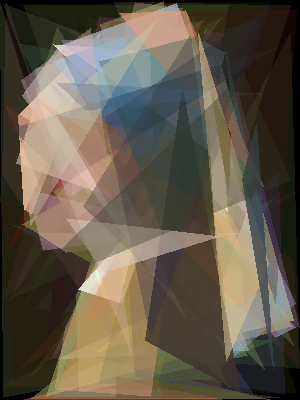

In [379]:
best_solution.render()

In [160]:
best_solution = genetic_algorithm_loop(
    population_size=100,
    n_iterations=10000,
    tournament_size=10,
    crossover_rate=0.90,
    mutation_rate=0.05,
    mutation_rate_decay=1e-4
)

Iteration 1 - Fitness: Avg: 9.89, Best: 9.60; Mutation rate: 0.050; 1.07s/iteration
Iteration 10 - Fitness: Avg: 9.23, Best: 9.00; Mutation rate: 0.050; 1.03s/iteration
Iteration 20 - Fitness: Avg: 8.96, Best: 8.70; Mutation rate: 0.050; 0.96s/iteration
Iteration 30 - Fitness: Avg: 8.83, Best: 8.53; Mutation rate: 0.050; 1.00s/iteration
Iteration 40 - Fitness: Avg: 8.74, Best: 8.45; Mutation rate: 0.050; 0.93s/iteration
Iteration 50 - Fitness: Avg: 8.69, Best: 8.38; Mutation rate: 0.050; 1.20s/iteration
Iteration 60 - Fitness: Avg: 8.66, Best: 8.32; Mutation rate: 0.050; 0.98s/iteration
Iteration 70 - Fitness: Avg: 8.62, Best: 8.32; Mutation rate: 0.050; 1.37s/iteration
Iteration 80 - Fitness: Avg: 8.62, Best: 8.29; Mutation rate: 0.050; 0.94s/iteration
Iteration 90 - Fitness: Avg: 8.57, Best: 8.23; Mutation rate: 0.050; 0.94s/iteration
Iteration 100 - Fitness: Avg: 8.57, Best: 8.22; Mutation rate: 0.050; 0.67s/iteration
Iteration 110 - Fitness: Avg: 8.59, Best: 8.21; Mutation rate: 0.